# Business Problem
Why is this company's profit margin declining despite revenue growth, and what three specific actions should management take to improve profitability?
# Desired Output
Identify whether revenue growth is accompanied by declining profit margins.
Determine the key factors contributing to poor profitability.
Develop an interactive Power BI dashboard to monitor business performance.
Recommend three specific, data-driven actions to improve profitability.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print('All libraries imported successfully!')

All libraries imported successfully!


In [2]:
df = pd.read_csv(
    "Superstore_Dataset.csv",
    encoding="latin1"
)

df.head()

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136
1,2,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820
2,3,CA-2016-138688,6/12/2016,6/16/2016,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,90036,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2,0.00,6.8714
3,4,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310
4,5,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2,0.20,2.5164


In [3]:
# Checking Structure
print("Shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

df.info()
df.describe(include="all")

Shape: (9994, 21)

Columns:
['Row ID', 'Order ID', 'Order Date', 'Ship Date', 'Ship Mode', 'Customer ID', 'Customer Name', 'Segment', 'Country', 'City', 'State', 'Postal Code', 'Region', 'Product ID', 'Category', 'Sub-Category', 'Product Name', 'Sales', 'Quantity', 'Discount', 'Profit']
<class 'pandas.DataFrame'>
RangeIndex: 9994 entries, 0 to 9993
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Row ID         9994 non-null   int64  
 1   Order ID       9994 non-null   str    
 2   Order Date     9994 non-null   str    
 3   Ship Date      9994 non-null   str    
 4   Ship Mode      9994 non-null   str    
 5   Customer ID    9994 non-null   str    
 6   Customer Name  9994 non-null   str    
 7   Segment        9994 non-null   str    
 8   Country        9994 non-null   str    
 9   City           9994 non-null   str    
 10  State          9994 non-null   str    
 11  Postal Code    9994 non-null   int64  


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
count,9994.000000,9994,9994,9994,9994,9994,9994,9994,9994,9994,...,9994.000000,9994,9994,9994,9994,9994,9994.000000,9994.000000,9994.000000,9994.000000
unique,NaN,5009,1237,1334,4,793,793,3,1,531,...,NaN,4,1862,3,17,1850,NaN,NaN,NaN,NaN
top,NaN,CA-2017-100111,9/5/2016,12/16/2015,Standard Class,WB-21850,William Brown,Consumer,United States,New York City,...,NaN,West,OFF-PA-10001970,Office Supplies,Binders,Staple envelope,NaN,NaN,NaN,NaN
freq,NaN,14,38,35,5968,37,37,5191,9994,915,...,NaN,3203,19,6026,1523,48,NaN,NaN,NaN,NaN
mean,4997.500000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,55190.379428,NaN,NaN,NaN,NaN,NaN,229.858001,3.789574,0.156203,28.656896
std,2885.163629,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,32063.693350,NaN,NaN,NaN,NaN,NaN,623.245101,2.225110,0.206452,234.260108
min,1.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,1040.000000,NaN,NaN,NaN,NaN,NaN,0.444000,1.000000,0.000000,-6599.978000
25%,2499.250000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,23223.000000,NaN,NaN,NaN,NaN,NaN,17.280000,2.000000,0.000000,1.728750
50%,4997.500000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,56430.500000,NaN,NaN,NaN,NaN,NaN,54.490000,3.000000,0.200000,8.666500
75%,7495.750000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,90008.000000,NaN,NaN,NaN,NaN,NaN,209.940000,5.000000,0.200000,29.364000


In [4]:
# Cleaning Column names
df.columns = (
    df.columns.str.strip()
    .str.lower()
    .str.replace(r"\s+", "_", regex=True)
)

print(df.columns.tolist())

['row_id', 'order_id', 'order_date', 'ship_date', 'ship_mode', 'customer_id', 'customer_name', 'segment', 'country', 'city', 'state', 'postal_code', 'region', 'product_id', 'category', 'sub-category', 'product_name', 'sales', 'quantity', 'discount', 'profit']


In [5]:
# Checking Missing Values
missing = df.isnull().sum()

print(missing[missing > 0])
print("Total missing values:", df.isnull().sum().sum())

Series([], dtype: int64)
Total missing values: 0


In [6]:
# Checking Duplicate Records
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 0


In [8]:
# Converting date columns in correct format
for col in ["order_date", "ship_date"]:
    if col in df.columns:
        df[col] = pd.to_datetime(
            df[col], errors="coerce"
        )

print(df[["order_date", "ship_date"]].dtypes)

order_date    datetime64[us]
ship_date     datetime64[us]
dtype: object


In [9]:
# Checking Numerical Columns
numeric_cols = ["sales", "profit", "quantity", "discount"]

for col in numeric_cols:
    if col in df.columns:
        df[col] = pd.to_numeric(
            df[col], errors="coerce"
        )

print(df[numeric_cols].describe())

              sales       profit     quantity     discount
count   9994.000000  9994.000000  9994.000000  9994.000000
mean     229.858001    28.656896     3.789574     0.156203
std      623.245101   234.260108     2.225110     0.206452
min        0.444000 -6599.978000     1.000000     0.000000
25%       17.280000     1.728750     2.000000     0.000000
50%       54.490000     8.666500     3.000000     0.200000
75%      209.940000    29.364000     5.000000     0.200000
max    22638.480000  8399.976000    14.000000     0.800000


In [10]:
# New Analytical Columns
df["order_year"] = df["order_date"].dt.year
df["order_month"] = df["order_date"].dt.month
df["order_month_name"] = df["order_date"].dt.strftime("%b")

df["shipping_days"] = (
    df["ship_date"] - df["order_date"]
).dt.days

df["profit_margin"] = np.where(
    df["sales"] != 0,
    df["profit"] / df["sales"] * 100,
    np.nan
)

df.head()

,row_id,order_id,order_date,ship_date,ship_mode,customer_id,customer_name,segment,country,city,...,product_name,sales,quantity,discount,profit,order_year,order_month,order_month_name,shipping_days,profit_margin
0,1,CA-2016-152156,2016-11-08,2016-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136,2016,11,Nov,3,16.00
1,2,CA-2016-152156,2016-11-08,2016-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820,2016,11,Nov,3,30.00
2,3,CA-2016-138688,2016-06-12,2016-06-16,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,Self-Adhesive Address Labels for Typewriters b...,14.6200,2,0.00,6.8714,2016,6,Jun,4,47.00
3,4,US-2015-108966,2015-10-11,2015-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310,2015,10,Oct,7,-40.00
4,5,US-2015-108966,2015-10-11,2015-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,Eldon Fold 'N Roll Cart System,22.3680,2,0.20,2.5164,2015,10,Oct,7,11.25


In [11]:
# Exporting Cleaned dataset
df.to_csv("superstore_cleaned.csv", index=False)

print("Cleaned dataset saved!")

Cleaned dataset saved!


In [12]:
# Overall Business Performance
total_sales = df["sales"].sum()
total_profit = df["profit"].sum()
total_orders = df["order_id"].nunique()
total_quantity = df["quantity"].sum()

overall_margin = (
    total_profit / total_sales * 100
    if total_sales != 0 else np.nan
)

print("Total Sales:", round(total_sales, 2))
print("Total Profit:", round(total_profit, 2))
print("Unique Orders:", total_orders)
print("Units Sold:", total_quantity)
print("Profit Margin:", round(overall_margin, 2), "%")

Total Sales: 2297200.86
Total Profit: 286397.02
Unique Orders: 5009
Units Sold: 37873
Profit Margin: 12.47 %


In [13]:
# Category and Sub-Category Performance
category_analysis = (
    df.groupby("category")
      .agg(
          sales=("sales", "sum"),
          profit=("profit", "sum"),
          quantity=("quantity", "sum")
      )
      .sort_values("sales", ascending=False)
)

category_analysis["profit_margin_pct"] = (
    category_analysis["profit"]
    / category_analysis["sales"] * 100
)

print(category_analysis.round(2))

                     sales     profit  quantity  profit_margin_pct
category                                                          
Technology       836154.03  145454.95      6939              17.40
Furniture        741999.80   18451.27      8028               2.49
Office Supplies  719047.03  122490.80     22906              17.04


In [14]:
# Regional Performance
region_analysis = (
    df.groupby("region")
      .agg(
          sales=("sales", "sum"),
          profit=("profit", "sum"),
          orders=("order_id", "nunique")
      )
)

region_analysis["profit_margin_pct"] = (
    region_analysis["profit"]
    / region_analysis["sales"] * 100
)

print(region_analysis.round(2))

             sales     profit  orders  profit_margin_pct
region                                                  
Central  501239.89   39706.36    1175               7.92
East     678781.24   91522.78    1401              13.48
South    391721.90   46749.43     822              11.93
West     725457.82  108418.45    1611              14.94


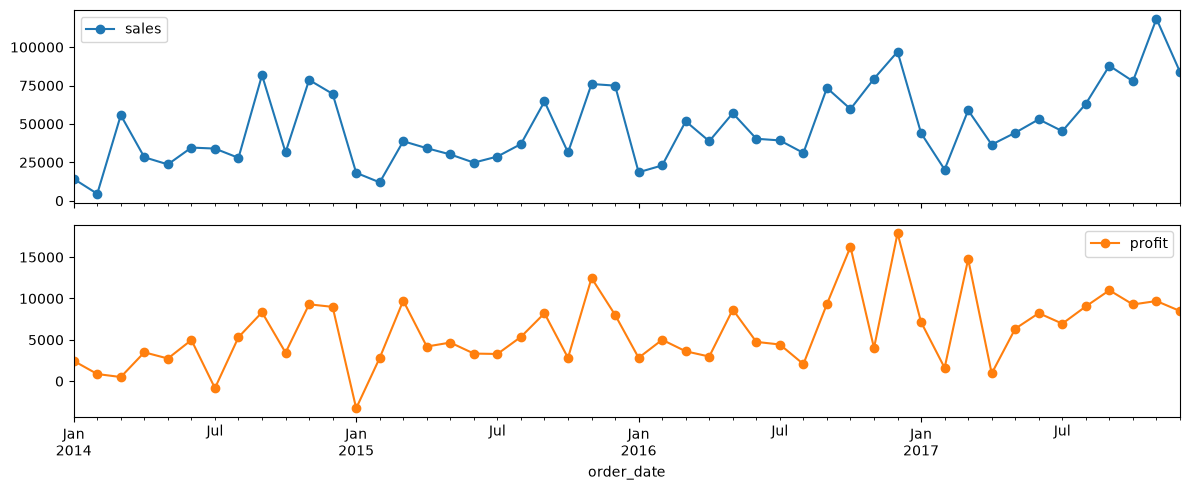

In [15]:
# Monthly sales and profit trends
monthly = (
    df.groupby(df["order_date"].dt.to_period("M"))
      .agg(
          sales=("sales", "sum"),
          profit=("profit", "sum")
      )
)

monthly.index = monthly.index.to_timestamp()

monthly[["sales", "profit"]].plot(
    figsize=(12, 5),
    marker="o",
    subplots=True
)

plt.tight_layout()
plt.show()

          discount  sales  profit
discount      1.00  -0.03   -0.22
sales        -0.03   1.00    0.48
profit       -0.22   0.48    1.00


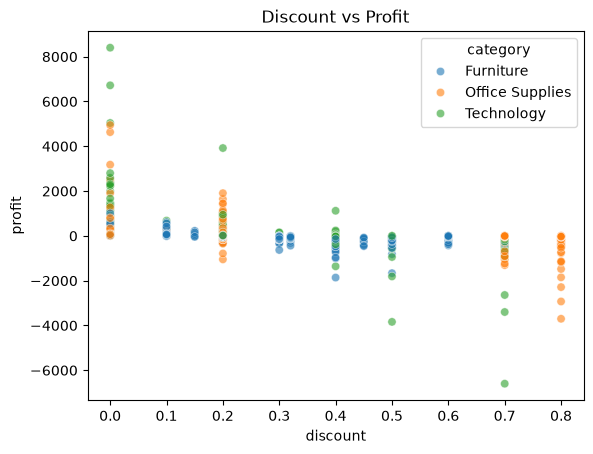

In [16]:
# Relationship of Discount & Profit
print(
    df[["discount", "sales", "profit"]]
    .corr()
    .round(2)
)

sns.scatterplot(
    data=df,
    x="discount",
    y="profit",
    hue="category",
    alpha=0.6
)

plt.title("Discount vs Profit")
plt.show()

In [17]:
# Identifying Loss-Making Products
product_analysis = (
    df.groupby(["product_id", "product_name"])
      .agg(
          sales=("sales", "sum"),
          profit=("profit", "sum"),
          quantity=("quantity", "sum")
      )
      .sort_values("profit")
)

print(product_analysis.head(10).round(2))

                                                                       sales  \
product_id      product_name                                                   
TEC-MA-10000418 Cubify CubeX 3D Printer Double Head Print           11099.96   
TEC-MA-10000822 Lexmark MX611dhe Monochrome Laser Printer           16829.90   
TEC-MA-10004125 Cubify CubeX 3D Printer Triple Head Print            7999.98   
FUR-TA-10000198 Chromcraft Bull-Nose Wood Oval Conference Table...   9917.64   
FUR-TA-10001889 Bush Advantage Collection Racetrack Conference ...   9544.72   
OFF-BI-10004995 GBC DocuBind P400 Electric Binding System           17965.07   
TEC-MA-10002412 Cisco TelePresence System EX90 Videoconferencin...  22638.48   
OFF-SU-10002881 Martin Yale Chadless Opener Electric Letter Opener  16656.20   
FUR-TA-10001950 Balt Solid Wood Round Tables                         6518.75   
FUR-TA-10004289 BoxOffice By Design Rectangular and Half-Moon M...   1706.25   

                                       

In [18]:
# Yearly Performance
yearly = (
    df.groupby(df["order_date"].dt.year)
      .agg(
          sales=("sales", "sum"),
          profit=("profit", "sum")
      )
)

yearly["profit_margin_pct"] = (
    yearly["profit"] / yearly["sales"] * 100
)

yearly["sales_growth_pct"] = (
    yearly["sales"].pct_change() * 100
)

yearly["margin_change_pp"] = (
    yearly["profit_margin_pct"].diff()
)

print(yearly.round(2))

                sales    profit  profit_margin_pct  sales_growth_pct  \
order_date                                                             
2014        484247.50  49543.97              10.23               NaN   
2015        470532.51  61618.60              13.10             -2.83   
2016        609205.60  81795.17              13.43             29.47   
2017        733215.26  93439.27              12.74             20.36   

            margin_change_pp  
order_date                    
2014                     NaN  
2015                    2.86  
2016                    0.33  
2017                   -0.68  
